# Housing costs by zip code: Albert
**Datathon for Social Good 2026 · Bay Area Affordability Project**

The **typical rent and typical home value in every Bay Area zip code**, the change since before the pandemic, a price-to-rent ratio, the income needed to afford the typical rent, and a 0–100 affordability score. Keyed to the same zip codes as Anna's essential-services table (`03_anna_essential_services.ipynb`), so the two join one-to-one on `zipcode`.

**Where the numbers come from**
- **Typical rent: Zillow Observed Rent Index (ZORI)**, Zillow's monthly typical rent per zip code, smoothed and adjusted so it reflects the whole rental stock rather than just whatever is listed this month.
- **Typical home value: Zillow Home Value Index (ZHVI)**, Zillow's typical (middle third) home value per zip code, single-family homes and condos.
- **Cross-check: datathon Zillow listings.** Median asking rent of the `FOR_RENT` listings in the provided Zillow dataset, from Anna's table.

Both indexes are free public downloads from Zillow Research (zillow.com/research/data). They're used instead of computing medians from the datathon's 1.5–4 GB Zillow listing files, which Google Drive blocked from downloading ("quota exceeded") on Nov 14. The listing-based version of this notebook is kept as `04b_albert_listing_costs.ipynb` for when the files can be read.

**How to run:** Colab or locally, `Run all`. It downloads the two Zillow files; if that fails it uses the Bay Area copies saved in `data/zillow_research/`. Anna's table is read from the repo if present.

## 1. Setup

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd

# Find this folder (datathon/albert_upload) wherever the notebook is started from
def find_albert_dir():
    for d in [Path.cwd(), *Path.cwd().parents]:
        for cand in [d, d / "albert_upload", d / "datathon" / "albert_upload",
                     d / "datathon-social-good" / "datathon" / "albert_upload"]:
            if (cand / "notebooks" / "04_albert_housing_costs.ipynb").exists():
                return cand
    return None

ALBERT = find_albert_dir()
IN_COLAB = "google.colab" in str(globals().get("get_ipython", lambda: "")())
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    TABLE_DIR = FIG_DIR = "/content/drive/MyDrive/datathon_outputs"
elif ALBERT is not None:
    TABLE_DIR, FIG_DIR = str(ALBERT / "outputs" / "tables"), str(ALBERT / "outputs" / "figures")
else:
    TABLE_DIR, FIG_DIR = "outputs/tables", "outputs/figures"
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
print("albert_upload folder:", ALBERT, "\nTables ->", TABLE_DIR, "\nFigures ->", FIG_DIR)

ZORI_URL = "https://files.zillowstatic.com/research/public_csvs/zori/Zip_zori_uc_sfrcondomfr_sm_month.csv"
ZHVI_URL = "https://files.zillowstatic.com/research/public_csvs/zhvi/Zip_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
# Bay Area rows of the two files, saved in the repo: used if Zillow can't be reached
SAVED = {"rent": "data/zillow_research/zori_bay_area.csv", "value": "data/zillow_research/zhvi_bay_area.csv"}
USE_SAVED_ONLY = False      # True = skip the download and use the saved Bay Area copies

BAY_AREA = ["Alameda County", "Contra Costa County", "Marin County", "Napa County",
            "San Francisco County", "San Mateo County", "Santa Clara County",
            "Solano County", "Sonoma County"]

albert_upload folder: c:\Users\zliu7\Documents\Projects\Datathon\datathon-social-good\datathon\albert_upload 
Tables -> c:\Users\zliu7\Documents\Projects\Datathon\datathon-social-good\datathon\albert_upload\outputs\tables 
Figures -> c:\Users\zliu7\Documents\Projects\Datathon\datathon-social-good\datathon\albert_upload\outputs\figures


## 2. Load Zillow's rent and home value indexes
Each file has one row per US zip code and one column per month. Keep California zip codes in the 9 Bay Area counties, and keep the **December value of each year** plus the **latest month**. ZHVI is about 120 MB, so this cell can take a few minutes. If Zillow can't be reached (no internet, or the download is refused), the notebook uses the Bay Area rows saved in `data/zillow_research/` (September 2026) and says so.

In [2]:
def read_zillow_csv(url, name):
    """Download Zillow's file like a browser does; fall back to the saved Bay Area copy."""
    saved = (ALBERT / SAVED[name]) if ALBERT is not None else Path(SAVED[name])
    if not USE_SAVED_ONLY:
        try:
            df = pd.read_csv(url, dtype={"RegionName": str},
                             storage_options={"User-Agent": "Mozilla/5.0 (datathon notebook)"})
            print(f"{name}: downloaded from Zillow ({len(df):,} US zip codes)")
            return df, "download"
        except Exception as e:
            print(f"{name}: couldn't download from Zillow ({type(e).__name__}: {str(e)[:120]})")
    if saved.exists():
        print(f"{name}: using the saved Bay Area copy {saved}")
        return pd.read_csv(saved, dtype={"RegionName": str}), "saved"
    raise FileNotFoundError(f"No internet copy and no saved copy at {saved}")

def load_zillow_index(url, name):
    df, how = read_zillow_csv(url, name)
    df = df[(df["State"] == "CA") & df["CountyName"].isin(BAY_AREA)].copy()
    date_cols = [c for c in df.columns if len(c) == 10 and c[:2] in ("19", "20") and c[4] == "-"]
    latest = date_cols[-1]
    keep = [c for c in date_cols if c[5:7] == "12" and c >= "2015"]
    if latest not in keep:
        keep.append(latest)
    # Refresh the saved copy after a successful download (Bay Area rows, December + latest only)
    if how == "download" and ALBERT is not None:
        out_path = ALBERT / SAVED[name]
        out_path.parent.mkdir(parents=True, exist_ok=True)
        id_cols = ["RegionID", "SizeRank", "RegionName", "RegionType", "StateName", "State", "City", "Metro", "CountyName"]
        df[[c for c in id_cols if c in df.columns] + keep].to_csv(out_path, index=False)
    out = df[["RegionName", "City", "CountyName"] + keep].rename(
        columns={"RegionName": "zipcode", "City": "city", "CountyName": "county"})
    out["zipcode"] = out["zipcode"].astype(str).str.zfill(5)
    out = out.rename(columns={c: f"{name}_{c[:4]}" for c in keep if c != latest})
    out = out.rename(columns={latest: f"{name}_latest"})
    print(f"{name}: {len(out)} Bay Area zip codes, latest month {latest}")
    return out, latest

zori, LATEST_RENT_MONTH = load_zillow_index(ZORI_URL, "rent")
zhvi, LATEST_VALUE_MONTH = load_zillow_index(ZHVI_URL, "value")

rent: downloaded from Zillow (8,340 US zip codes)
rent: 210 Bay Area zip codes, latest month 2026-09-30
value: downloaded from Zillow (26,265 US zip codes)
value: 274 Bay Area zip codes, latest month 2026-09-30


## 3. Zip codes: start from Anna's table
Anna's `essentials_by_zip` has the 293 Bay Area zip codes found in the datathon Zillow data, with `n_homes` and `low_data`. Starting from it keeps the two tables row-for-row. Zip codes that Zillow's indexes cover but Anna's table doesn't are added at the end, with `in_anna_table = False`.

In [3]:
anna_paths = ([str(ALBERT.parent / "anna_upload" / "outputs" / "tables" / "anna_essentials_by_zip.csv")] if ALBERT else []) + [
    "/content/drive/MyDrive/datathon_outputs/essentials_by_zip.csv"]
anna_path = next((p for p in anna_paths if os.path.exists(p)), None)

ids = pd.concat([zori[["zipcode", "city", "county"]], zhvi[["zipcode", "city", "county"]]]).drop_duplicates("zipcode")
if anna_path:
    anna = pd.read_csv(anna_path, dtype={"zipcode": str})
    base = anna[["zipcode", "city", "county", "n_homes", "low_data"]].copy()
    base["in_anna_table"] = True
    extra = ids[~ids["zipcode"].isin(base["zipcode"])].assign(in_anna_table=False)
    base = pd.concat([base, extra], ignore_index=True)
    listing = anna[["zipcode", "median_rent", "n_rentals", "rent_per_bedroom"]].rename(columns={
        "median_rent": "listing_median_rent", "n_rentals": "listing_n_rentals",
        "rent_per_bedroom": "listing_rent_per_bedroom"})
    print(f"Anna's table: {len(anna)} zips; {len(extra)} more zips only in Zillow's indexes")
else:
    print("Anna's table not found: using the zip codes in Zillow's indexes only")
    base = ids.assign(n_homes=np.nan, low_data=np.nan, in_anna_table=False)
    listing = None

Anna's table: 293 zips; 0 more zips only in Zillow's indexes


## 4. Build the zip code table

In [4]:
by_zip = base.merge(zori.drop(columns=["city", "county"]), on="zipcode", how="left", validate="one_to_one")
by_zip = by_zip.merge(zhvi.drop(columns=["city", "county"]), on="zipcode", how="left", validate="one_to_one")
if listing is not None:
    by_zip = by_zip.merge(listing, on="zipcode", how="left", validate="one_to_one")

def pct_change(new, old):
    return ((by_zip[new] / by_zip[old] - 1) * 100).round(1)

by_zip["typical_rent"] = by_zip["rent_latest"]
by_zip["typical_home_value"] = by_zip["value_latest"]
by_zip["rent_change_2025_pct"] = pct_change("rent_2025", "rent_2024")            # Dec 2024 -> Dec 2025
by_zip["rent_change_since_2019_pct"] = pct_change("rent_latest", "rent_2019")    # Dec 2019 -> latest
by_zip["value_change_2025_pct"] = pct_change("value_2025", "value_2024")
by_zip["value_change_since_2019_pct"] = pct_change("value_latest", "value_2019")
# Years of rent to equal the price of the typical home
by_zip["price_to_rent_ratio"] = (by_zip["typical_home_value"] / (12 * by_zip["typical_rent"])).round(1)
# Yearly income needed so the typical rent is no more than 30% of income (HUD's rent-burden line)
by_zip["income_needed_for_rent"] = (by_zip["typical_rent"] * 12 / 0.30).round(-2)
if listing is not None:
    by_zip["zori_vs_listing_pct"] = pct_change("typical_rent", "listing_median_rent")

print(len(by_zip), "zip codes")
print("with typical rent (ZORI):", by_zip["typical_rent"].notna().sum())
print("with typical home value (ZHVI):", by_zip["typical_home_value"].notna().sum())
print("with both:", by_zip[["typical_rent", "typical_home_value"]].notna().all(axis=1).sum())

293 zip codes
with typical rent (ZORI): 210
with typical home value (ZHVI): 274
with both: 209


## 5. Affordability score (0–100)
Same method as Anna's access score, so the two sit on one scale. For zip codes with both a typical rent and a typical home value (and not `low_data` in Anna's table), rank them from cheapest (≈1) to most expensive (≈0) on each, average the two ranks and multiply by 100.

**The score is relative**: 80 means "cheaper than most Bay Area zip codes", not affordable for any given income. `income_needed_for_rent` is the absolute measure.

In [5]:
scored = by_zip[["typical_rent", "typical_home_value"]].notna().all(axis=1) & (by_zip["low_data"] != True)
ranks = pd.concat([1 - by_zip.loc[scored, c].rank(pct=True) for c in ["typical_rent", "typical_home_value"]], axis=1)
by_zip["affordability_score"] = (ranks.mean(axis=1) * 100).round(1)

show = ["zipcode", "city", "county", "typical_rent", "typical_home_value", "income_needed_for_rent", "affordability_score"]
print("MOST AFFORDABLE"); print(by_zip.sort_values("affordability_score", ascending=False)[show].head(10).to_string(index=False))
print("\nLEAST AFFORDABLE"); print(by_zip.sort_values("affordability_score")[show].head(10).to_string(index=False))

MOST AFFORDABLE
zipcode      city              county  typical_rent  typical_home_value  income_needed_for_rent  affordability_score
  94590   Vallejo       Solano County   2055.213384       460385.132474                 82200.0                 99.3
  94801  Richmond Contra Costa County   2263.194444       506861.623190                 90500.0                 98.3
  94601   Oakland      Alameda County   2215.958333       553360.437959                 88600.0                 96.9
  94621   Oakland      Alameda County   2411.666667       445422.937388                 96500.0                 96.9
  94533 Fairfield       Solano County   2317.893939       532197.926633                 92700.0                 96.9
  94509   Antioch Contra Costa County   2348.482738       536329.673206                 93900.0                 95.9
  94589   Vallejo       Solano County   2499.777778       494819.101160                100000.0                 95.5
  94591   Vallejo       Solano County   2318.741

## 6. Hand-check: Zillow's rent index vs. the datathon listings
Two independent measures of rent should broadly agree. Large gaps flag zip codes where one of them is unreliable (few listings, or listings of unusually small or large units).

In [6]:
if listing is not None:
    both = by_zip.dropna(subset=["typical_rent", "listing_median_rent"])
    both = both[both["listing_n_rentals"] >= 10]
    corr = both["typical_rent"].corr(both["listing_median_rent"])
    print(f"{len(both)} zips with both (10+ listings). Correlation: {corr:.2f}")
    print(f"Median gap (ZORI vs listings): {both['zori_vs_listing_pct'].median():+.1f}%")
    print(f"Within ±20%: {(both['zori_vs_listing_pct'].abs() <= 20).mean()*100:.0f}% of zips")
    cols = ["zipcode", "city", "typical_rent", "listing_median_rent", "listing_n_rentals", "zori_vs_listing_pct"]
    print("\nLargest gaps:")
    print(both.reindex(both["zori_vs_listing_pct"].abs().sort_values(ascending=False).index)[cols].head(10).to_string(index=False))

205 zips with both (10+ listings). Correlation: 0.81
Median gap (ZORI vs listings): +9.9%
Within ±20%: 77% of zips

Largest gaps:
zipcode          city  typical_rent  listing_median_rent  listing_n_rentals  zori_vs_listing_pct
  94563        Orinda   5238.888889               2895.0               11.0                 81.0
  95130      San Jose   4201.138889               2595.0               49.0                 61.9
  94129 San Francisco   6382.222222               3979.0               38.0                 60.4
  94303     Palo Alto   5522.142857               3447.5               66.0                 60.2
  95124      San Jose   4385.714286               2788.0               85.0                 57.3
  94109 San Francisco   4153.680653               2748.0              975.0                 51.2
  94574  Saint Helena   3225.000000               6500.0               40.0                -50.4
  94127 San Francisco   6083.333333               4097.5               10.0                 48

## 7. Summary by county (median across the county's zip codes)

In [7]:
g = by_zip.groupby("county")
county = pd.DataFrame({
    "zip_codes_with_rent": g["typical_rent"].count(),
    "typical_rent": g["typical_rent"].median(),
    "income_needed_for_rent": g["income_needed_for_rent"].median(),
    "rent_change_since_2019_pct": g["rent_change_since_2019_pct"].median(),
    "zip_codes_with_value": g["typical_home_value"].count(),
    "typical_home_value": g["typical_home_value"].median(),
    "value_change_since_2019_pct": g["value_change_since_2019_pct"].median(),
    "price_to_rent_ratio": g["price_to_rent_ratio"].median(),
}).loc[lambda d: d.index.isin(BAY_AREA)].sort_values("typical_rent", ascending=False).round(1)
county

,zip_codes_with_rent,typical_rent,income_needed_for_rent,rent_change_since_2019_pct,zip_codes_with_value,typical_home_value,value_change_since_2019_pct,price_to_rent_ratio
county,,,,,,,,
San Francisco County,25,4751.0,190000.0,43.0,26,1406331.1,4.5,24.5
Marin County,12,4235.0,169400.0,35.3,26,1500236.2,33.0,34.2
San Mateo County,18,3936.2,157450.0,26.0,27,1585012.7,29.2,38.0
Santa Clara County,48,3905.1,156200.0,26.9,57,1540697.7,42.6,31.8
Contra Costa County,32,3015.8,120600.0,26.8,39,772049.1,26.3,21.1
Napa County,6,2906.7,116250.0,27.7,8,898942.5,10.2,26.3
Alameda County,45,2878.9,115200.0,18.2,47,1147273.6,21.0,29.1
Sonoma County,14,2850.1,114000.0,27.3,32,800248.0,17.4,23.0
Solano County,10,2552.3,102100.0,28.1,12,579505.3,26.1,18.9


## 8. Save results

In [8]:
year_cols = [c for c in by_zip.columns if (c.startswith("rent_") or c.startswith("value_")) and c[-4:].isdigit()]
front = ["zipcode", "city", "county", "n_homes", "low_data", "in_anna_table",
         "typical_rent", "typical_home_value", "affordability_score", "income_needed_for_rent",
         "price_to_rent_ratio", "rent_change_2025_pct", "rent_change_since_2019_pct",
         "value_change_2025_pct", "value_change_since_2019_pct"]
front += [c for c in ["listing_median_rent", "listing_n_rentals", "listing_rent_per_bedroom", "zori_vs_listing_pct"] if c in by_zip]
by_zip = by_zip[front + sorted(year_cols)]
by_zip["rent_month"] = LATEST_RENT_MONTH
by_zip["value_month"] = LATEST_VALUE_MONTH
by_zip.to_csv(TABLE_DIR + "/albert_housing_by_zip.csv", index=False)
county.reset_index().to_csv(TABLE_DIR + "/albert_housing_by_county.csv", index=False)
print("Saved", by_zip.shape, "and", county.shape, "to", TABLE_DIR)

if anna_path:
    keep_anna = [c for c in anna.columns if c not in ["city", "county", "n_homes", "low_data",
                                                      "median_rent", "n_rentals", "rent_per_bedroom"]]
    combined = by_zip.merge(anna[keep_anna], on="zipcode", how="left", validate="one_to_one")
    combined.to_csv(TABLE_DIR + "/housing_plus_essentials_by_zip.csv", index=False)
    print("Saved housing_plus_essentials_by_zip.csv", combined.shape)

Saved (293, 43) and (9, 8) to c:\Users\zliu7\Documents\Projects\Datathon\datathon-social-good\datathon\albert_upload\outputs\tables
Saved housing_plus_essentials_by_zip.csv (293, 59)


## 9. Charts

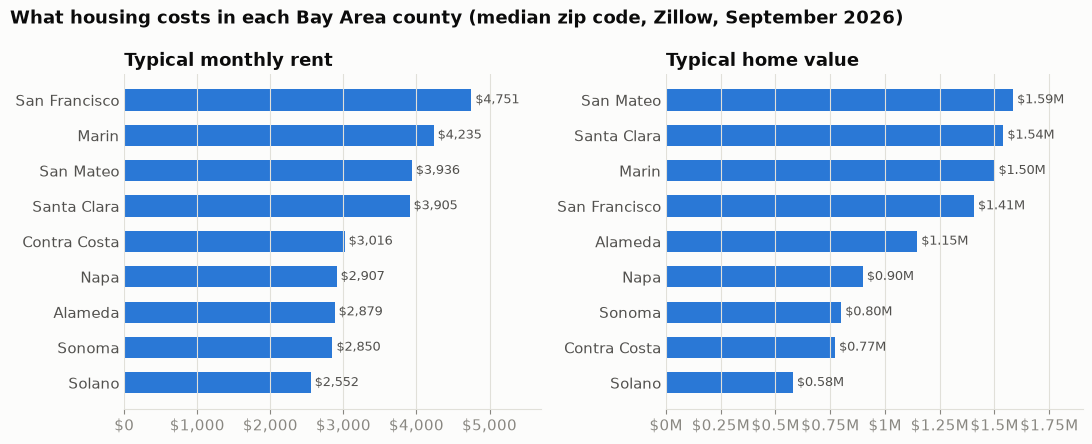

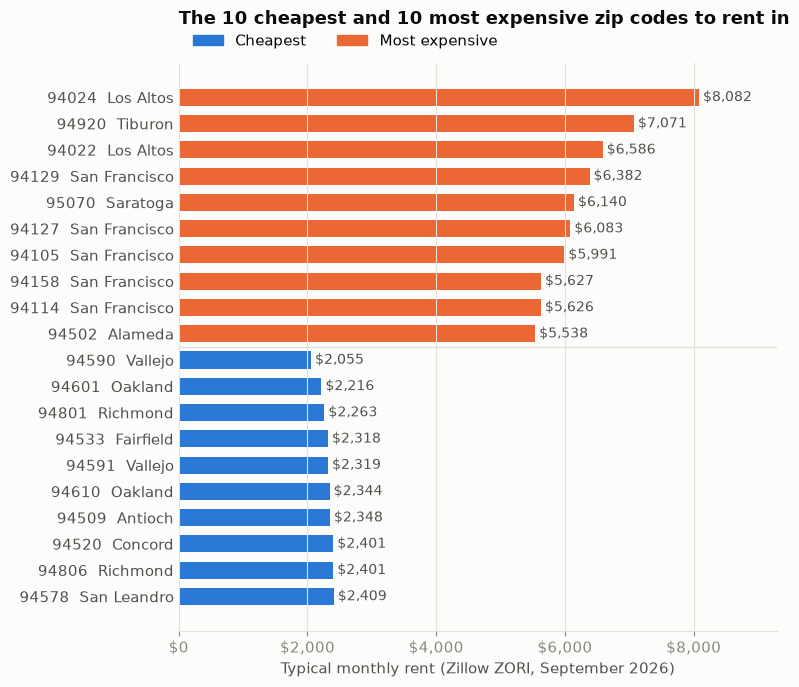

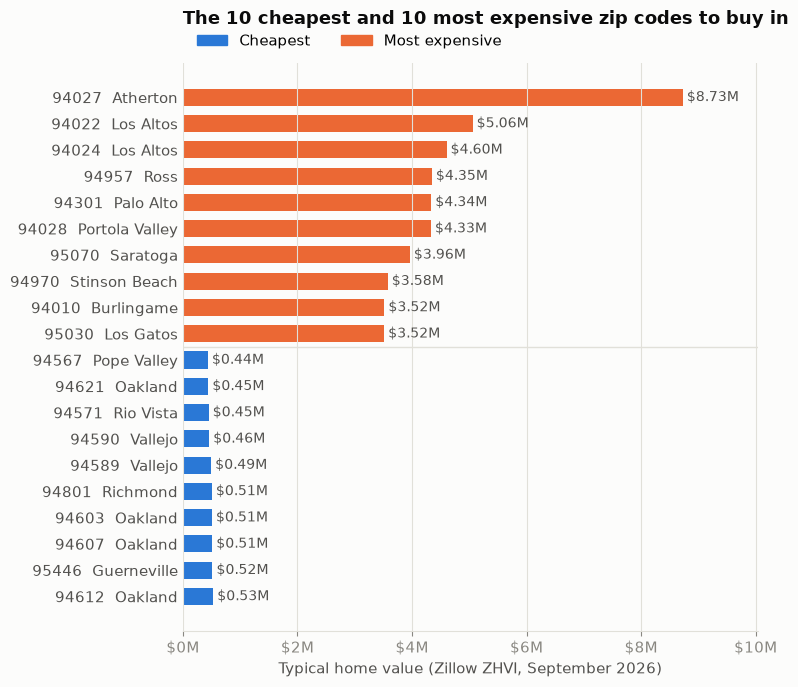

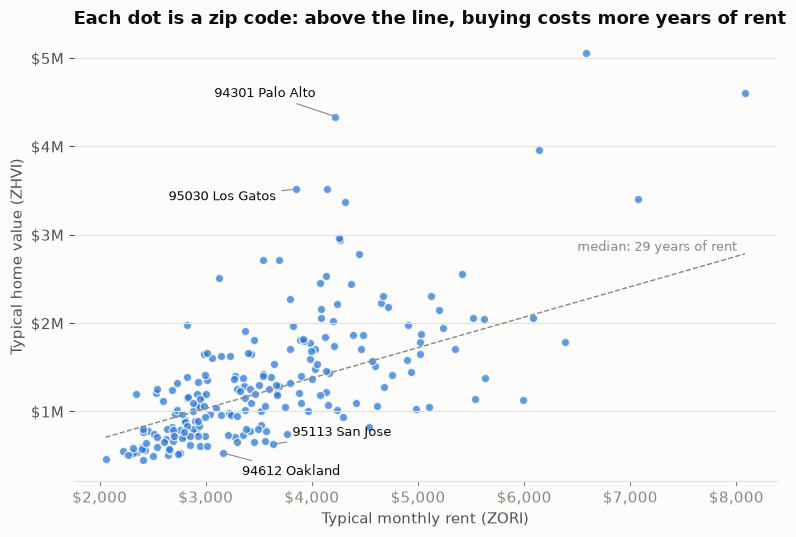

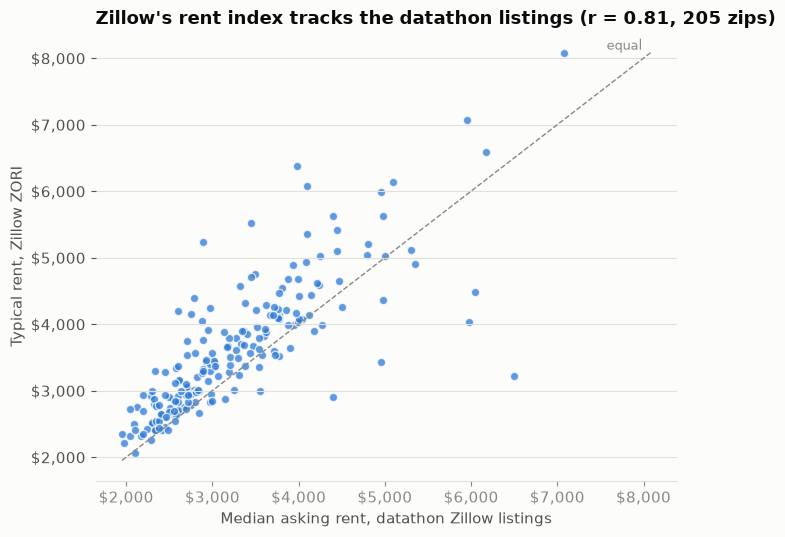

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": INK,
})
dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")
millions = FuncFormatter(lambda v, _: f"${v/1e6:g}M")
short = lambda s: s.replace(" County", "")
month_label = lambda m: pd.Timestamp(m).strftime("%B %Y")
ok = by_zip[by_zip["low_data"] != True]

# Chart 1: typical rent and home value by county
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, fmt, lab, title in [
        (axes[0], "typical_rent", dollars, lambda v: f" ${v:,.0f}", "Typical monthly rent"),
        (axes[1], "typical_home_value", millions, lambda v: f" ${v/1e6:.2f}M", "Typical home value")]:
    c = county.sort_values(col)
    bars = ax.barh([short(i) for i in c.index], c[col], color=BLUE, height=0.6)
    for bar, v in zip(bars, c[col]):
        ax.text(v, bar.get_y() + bar.get_height() / 2, lab(v), va="center", color=INK2, fontsize=9)
    ax.set_title(title); ax.xaxis.set_major_formatter(fmt)
    ax.tick_params(axis="y", length=0); ax.set_xlim(0, c[col].max() * 1.2)
fig.suptitle(f"What housing costs in each Bay Area county (median zip code, Zillow, {month_label(LATEST_RENT_MONTH)})",
             x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout(); plt.savefig(FIG_DIR + "/albert_cost_by_county.png", dpi=200); plt.show()

# Charts 2 and 3: the 10 cheapest and 10 most expensive zip codes
def ranking(col, fmt, lab, xlabel, title, fname):
    rel = ok.dropna(subset=[col])
    low, high = rel.nsmallest(10, col), rel.nlargest(10, col).iloc[::-1]
    both = pd.concat([low.iloc[::-1], high])
    fig, ax = plt.subplots(figsize=(8, 7))
    bars = ax.barh([f"{z}  {c}" for z, c in zip(both["zipcode"], both["city"])], both[col],
                   color=[BLUE] * len(low) + [ORANGE] * len(high), height=0.65)
    for bar, v in zip(bars, both[col]):
        ax.text(v, bar.get_y() + bar.get_height() / 2, lab(v), va="center", color=INK2, fontsize=10)
    ax.axhline(len(low) - 0.5, color=GRID, linewidth=1)
    ax.set_xlim(0, both[col].max() * 1.15); ax.xaxis.set_major_formatter(fmt)
    ax.set_xlabel(xlabel); ax.tick_params(axis="y", length=0)
    ax.legend(handles=[Patch(color=BLUE, label="Cheapest"), Patch(color=ORANGE, label="Most expensive")],
              loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
    ax.set_title(title, pad=28)
    plt.tight_layout(); plt.savefig(FIG_DIR + "/" + fname, dpi=200); plt.show()

ranking("typical_rent", dollars, lambda v: f" ${v:,.0f}",
        f"Typical monthly rent (Zillow ZORI, {month_label(LATEST_RENT_MONTH)})",
        "The 10 cheapest and 10 most expensive zip codes to rent in", "albert_rent_ranking.png")
ranking("typical_home_value", millions, lambda v: f" ${v/1e6:.2f}M",
        f"Typical home value (Zillow ZHVI, {month_label(LATEST_VALUE_MONTH)})",
        "The 10 cheapest and 10 most expensive zip codes to buy in", "albert_home_value_ranking.png")

# Chart 4: rent vs home value
rel = ok.dropna(subset=["typical_rent", "typical_home_value"])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.grid(axis="both")
ax.scatter(rel["typical_rent"], rel["typical_home_value"], s=36, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=1)
med = rel["price_to_rent_ratio"].median()
xs = np.linspace(rel["typical_rent"].min(), rel["typical_rent"].max(), 50)
ax.plot(xs, xs * 12 * med, color=MUTED, linewidth=1, linestyle="--")
ax.text(xs[-1], xs[-1] * 12 * med, f"median: {med:.0f} years of rent  ", color=MUTED, fontsize=9, ha="right", va="bottom")
for (_, r), dy in zip(rel.nlargest(2, "price_to_rent_ratio").iterrows(), [14, -8]):
    ax.annotate(f"{r['zipcode']} {r['city']}", (r["typical_rent"], r["typical_home_value"]), xytext=(-14, dy),
                textcoords="offset points", fontsize=9, color=INK, ha="right",
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
for (_, r), dy in zip(rel.nsmallest(2, "price_to_rent_ratio").iterrows(), [-16, 6]):
    ax.annotate(f"{r['zipcode']} {r['city']}", (r["typical_rent"], r["typical_home_value"]), xytext=(14, dy),
                textcoords="offset points", fontsize=9, color=INK,
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(millions)
ax.set_xlabel("Typical monthly rent (ZORI)"); ax.set_ylabel("Typical home value (ZHVI)")
ax.set_title("Each dot is a zip code: above the line, buying costs more years of rent")
plt.tight_layout(); plt.savefig(FIG_DIR + "/albert_rent_vs_value.png", dpi=200); plt.show()

# Chart 5: Zillow's rent index vs datathon listing rents (hand-check)
if listing is not None:
    rel = ok.dropna(subset=["typical_rent", "listing_median_rent"])
    rel = rel[rel["listing_n_rentals"] >= 10]
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.grid(axis="both")
    ax.scatter(rel["listing_median_rent"], rel["typical_rent"], s=36, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=1)
    lo, hi = min(rel["listing_median_rent"].min(), rel["typical_rent"].min()), max(rel["listing_median_rent"].max(), rel["typical_rent"].max())
    ax.plot([lo, hi], [lo, hi], color=MUTED, linewidth=1, linestyle="--")
    ax.text(hi, hi, "equal  ", color=MUTED, fontsize=9, ha="right", va="bottom")
    ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
    ax.set_xlabel("Median asking rent, datathon Zillow listings")
    ax.set_ylabel("Typical rent, Zillow ZORI")
    ax.set_title(f"Zillow's rent index tracks the datathon listings (r = {rel['typical_rent'].corr(rel['listing_median_rent']):.2f}, {len(rel)} zips)")
    plt.tight_layout(); plt.savefig(FIG_DIR + "/albert_rent_check.png", dpi=200); plt.show()

## 10. Numbers for the write-up

In [10]:
r = ok.dropna(subset=["typical_rent"]); v = ok.dropna(subset=["typical_home_value"])
print(f"Rent month: {LATEST_RENT_MONTH} | value month: {LATEST_VALUE_MONTH}")
print(f"Zips with typical rent: {len(r)} | with typical home value: {len(v)}")
print(f"Median zip: rent ${r['typical_rent'].median():,.0f}/mo, home value ${v['typical_home_value'].median():,.0f}")
print(f"Rent range: ${r['typical_rent'].min():,.0f} ({r.loc[r['typical_rent'].idxmin(), 'city']} {r.loc[r['typical_rent'].idxmin(), 'zipcode']})"
      f" to ${r['typical_rent'].max():,.0f} ({r.loc[r['typical_rent'].idxmax(), 'city']} {r.loc[r['typical_rent'].idxmax(), 'zipcode']})")
print(f"Value range: ${v['typical_home_value'].min():,.0f} ({v.loc[v['typical_home_value'].idxmin(), 'city']} {v.loc[v['typical_home_value'].idxmin(), 'zipcode']})"
      f" to ${v['typical_home_value'].max():,.0f} ({v.loc[v['typical_home_value'].idxmax(), 'city']} {v.loc[v['typical_home_value'].idxmax(), 'zipcode']})")
print(f"Income needed for the median zip's rent (30% rule): ${r['income_needed_for_rent'].median():,.0f}")
print(f"Median rent change since Dec 2019: {r['rent_change_since_2019_pct'].median():+.1f}% "
      f"({r['rent_change_since_2019_pct'].notna().sum()} zips with 2019 data)")
print(f"Median rent change during 2025: {r['rent_change_2025_pct'].median():+.1f}%")
print(f"Median home value change since Dec 2019: {v['value_change_since_2019_pct'].median():+.1f}%")
print(f"Median price-to-rent ratio: {ok['price_to_rent_ratio'].median():.1f} years")

Rent month: 2026-09-30 | value month: 2026-09-30
Zips with typical rent: 210 | with typical home value: 252
Median zip: rent $3,422/mo, home value $1,210,080
Rent range: $2,055 (Vallejo 94590) to $8,082 (Los Altos 94024)
Value range: $437,781 (Pope Valley 94567) to $8,728,582 (Atherton 94027)
Income needed for the median zip's rent (30% rule): $136,900
Median rent change since Dec 2019: +26.6% (119 zips with 2019 data)
Median rent change during 2025: +3.6%
Median home value change since Dec 2019: +25.7%
Median price-to-rent ratio: 28.7 years
